In [ ]:
# 1. NUKE EVERYTHING (Uninstall all conflicting libraries)
!pip uninstall -y paddlepaddle paddlepaddle-gpu paddleocr paddlex numpy langchain langchain-community

# 2. INSTALL STABLE VERSIONS (Force the exact versions that work together)
# We install paddlepaddle FIRST to ensure OCR doesn't grab the beta version
!pip install "paddlepaddle==2.6.1" -f https://www.paddlepaddle.org.cn/whl/linux/mkl/avx/stable.html
!pip install "paddleocr==2.7.3" "numpy<2.0" "langchain==0.1.0" "langchain-community==0.0.10"

Found existing installation: paddlepaddle 2.6.1
Uninstalling paddlepaddle-2.6.1:
  Successfully uninstalled paddlepaddle-2.6.1
Found existing installation: paddleocr 3.3.3
Uninstalling paddleocr-3.3.3:
  Successfully uninstalled paddleocr-3.3.3
Found existing installation: paddlex 3.3.13
Uninstalling paddlex-3.3.13:
  Successfully uninstalled paddlex-3.3.13
Found existing installation: numpy 1.26.4
Uninstalling numpy-1.26.4:
  Successfully uninstalled numpy-1.26.4
Found existing installation: langchain 0.1.0
Uninstalling langchain-0.1.0:
  Successfully uninstalled langchain-0.1.0
Found existing installation: langchain-community 0.0.10
Uninstalling langchain-community-0.0.10:
  Successfully uninstalled langchain-community-0.0.10
Looking in links: https://www.paddlepaddle.org.cn/whl/linux/mkl/avx/stable.html
  Using cached https://paddle-wheel.bj.bcebos.com/2.6.1/linux/linux-cpu-mkl-avx/paddlepaddle-2.6.1-cp312-cp312-linux_x86_64.whl (125.9 MB)
  Using cached numpy-2.4.1-cp312-cp312-many

  Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (61 kB)
  Using cached langchain-0.1.0-py3-none-any.whl.metadata (13 kB)
  Using cached langchain_community-0.0.10-py3-none-any.whl.metadata (7.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.0/780.0 kB 12.4 MB/s eta 0:00:00
Using cached langchain-0.1.0-py3-none-any.whl (797 kB)
Using cached langchain_community-0.0.10-py3-none-any.whl (1.5 MB)
Using cached numpy-1.26.4-cp312-cp312-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (18.0 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 9.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 67.1/67.1 MB 9.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.9/60.9 MB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 948.0/948.0 kB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 299.4/299.4 kB 23.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.0/132.0 kB 

In [ ]:
import paddle
import numpy as np
print(f"Paddle Version: {paddle.__version__}")  # MUST say 2.6.1
print(f"NumPy Version: {np.__version__}")      # MUST say 1.26.x

Paddle Version: 2.6.1
NumPy Version: 1.26.4


In [ ]:
import cv2
from matplotlib import pyplot as plt
from pdf2image import convert_from_path
import pytesseract
import easyocr

# Import PaddleOCR safely
try:
    from paddleocr import PaddleOCR
    print("PaddleOCR imported successfully!")
except ImportError as e:
    print(f"Import failed: {e}")

print(f"NumPy Version: {np.__version__}") # Should be 1.26.x

PaddleOCR imported successfully!
NumPy Version: 1.26.4


Document Loaded Successfully.


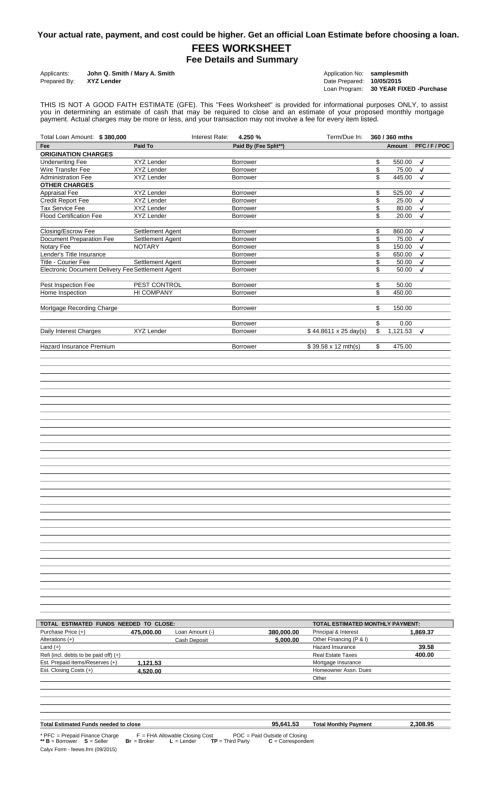

In [ ]:
# Convert PDF to Image (OCR works best on images)
images = convert_from_path('LenderFeesWorksheetNew.pdf')
img = np.array(images[0]) # Taking the first page

# Helper function to display results
def show_image(img):
    plt.figure(figsize=(10,10))
    plt.imshow(img)
    plt.axis('off')
    plt.show()

print("Document Loaded Successfully.")
show_image(img)

In [ ]:
# Tesseract Execution
print("--- Running Tesseract ---")
# Converting to grayscale often helps Tesseract
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
text_tesseract = pytesseract.image_to_string(gray)

print(text_tesseract)

--- Running Tesseract ---
Your actual rate, payment, and cost could be higher. Get an official Loan Estimate before choosing a loan.

FEES WORKSHEET
Fee Details and Summary

Applicants: John Q. Smith / Mary A. Smith Application No: samplesmith
Prepared By: XYZ Lender Date Prepared: 10/05/2015
Loan Program: 30 YEAR FIXED -Purchase

THIS IS NOT A GOOD FAITH ESTIMATE (GFE). This "Fees Worksheet" is provided for informational purposes ONLY, to assist
you in determining an estimate of cash that may be required to close and an estimate of your proposed monthly mortgage
payment. Actual charges may be more or less, and your transaction may not involve a fee for every item listed.

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

 

Total Loan Amount: $ 380,000 Interest Rate: 4.250% Term/Due In: 360/3

In [ ]:
# PaddleOCR Execution
print("--- Running PaddleOCR ---")

# Initialize the engine
# We keep 'use_angle_cls=True' here, which is enough!
paddle = PaddleOCR(use_angle_cls=True, lang='en')

# Run OCR (Removed 'cls=True' to fix the TypeError)
result_paddle = paddle.ocr(img)

# Print results
# The 'result_paddle' is a list of lists, so we loop through it
if result_paddle[0] is not None:
    for line in result_paddle[0]:
        text_detected = line[1][0]
        print(text_detected)
else:
    print("No text detected.")

--- Running PaddleOCR ---
download https://paddleocr.bj.bcebos.com/PP-OCRv3/english/en_PP-OCRv3_det_infer.tar to /root/.paddleocr/whl/det/en/en_PP-OCRv3_det_infer/en_PP-OCRv3_det_infer.tar


100%|██████████| 4.00M/4.00M [00:16<00:00, 247kiB/s] 


download https://paddleocr.bj.bcebos.com/PP-OCRv4/english/en_PP-OCRv4_rec_infer.tar to /root/.paddleocr/whl/rec/en/en_PP-OCRv4_rec_infer/en_PP-OCRv4_rec_infer.tar


100%|██████████| 10.2M/10.2M [00:02<00:00, 4.39MiB/s]


download https://paddleocr.bj.bcebos.com/dygraph_v2.0/ch/ch_ppocr_mobile_v2.0_cls_infer.tar to /root/.paddleocr/whl/cls/ch_ppocr_mobile_v2.0_cls_infer/ch_ppocr_mobile_v2.0_cls_infer.tar


100%|██████████| 2.19M/2.19M [00:14<00:00, 150kiB/s]

[2026/01/28 00:17:59] ppocr DEBUG: Namespace(help='==SUPPRESS==', use_gpu=False, use_xpu=False, use_npu=False, ir_optim=True, use_tensorrt=False, min_subgraph_size=15, precision='fp32', gpu_mem=500, gpu_id=0, image_dir=None, page_num=0, det_algorithm='DB', det_model_dir='/root/.paddleocr/whl/det/en/en_PP-OCRv3_det_infer', det_limit_side_len=960, det_limit_type='max', det_box_type='quad', det_db_thresh=0.3, det_db_box_thresh=0.6, det_db_unclip_ratio=1.5, max_batch_size=10, use_dilation=False, det_db_score_mode='fast', det_east_score_thresh=0.8, det_east_cover_thresh=0.1, det_east_nms_thresh=0.2, det_sast_score_thresh=0.5, det_sast_nms_thresh=0.2, det_pse_thresh=0, det_pse_box_thresh=0.85, det_pse_min_area=16, det_pse_scale=1, scales=[8, 16, 32], alpha=1.0, beta=1.0, fourier_degree=5, rec_algorithm='SVTR_LCNet', rec_model_dir='/root/.paddleocr/whl/rec/en/en_PP-OCRv4_rec_infer', rec_image_inverse=True, rec_image_shape='3, 48, 320', rec_batch_num=6, max_text_length=25, rec_char_dict_path='

[2026/01/28 00:18:01] ppocr DEBUG: dt_boxes num : 162, elapsed : 0.44777345657348633
[2026/01/28 00:18:01] ppocr DEBUG: cls num  : 162, elapsed : 0.47841572761535645
[2026/01/28 00:18:12] ppocr DEBUG: rec_res num  : 162, elapsed : 10.607764959335327
Your actual rate, payment, and cost could be higher. Get an official Loan Estimate before choosing a loan..
FEES WORKSHEET
Fee Details and Summary.
Applicants:
John Q. Smith / Mary A. Smith.
Application No:
samplesmith
Prepared By:
XYZ Lender
Date Prepared:
10/05/2015
 Loan Program:
30 YEAR FIXED -Purchase
THIS IS NOT A GOOD FAITH ESTIMATE (GFE). This "Fees Worksheet" is provided for informational purposes ONLY, to assist
payment. Actual charges may be more or less, and your transaction may not involve a fee for every item listed.
Total Loan Amount: $ 380,000
Interest Rate:
4.250 %
Term/Due In:
360 / 360 mths
Fee
 Paid To
Paid By (Fee Split**)
Amount PFC/F/POC
 ORIGINATION CHARGES
Underwriting Fee
XYZ Lender
Borrower
550.00
Wire Transfer Fe

In [ ]:
# EasyOCR Execution
print("--- Running EasyOCR ---")
reader = easyocr.Reader(['en'])
result_easy = reader.readtext(img)

# Print results
for (bbox, text, prob) in result_easy:
    print(text)

--- Running EasyOCR ---
Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% CompleteYour actual rate; payment; and cost could be higher: Get an official Loan Estimate before choosing a loan.
FEES WORKSHEET
Fee Details and Summary
Applicants:
John Q. Smith
A Smith
Application No:
samplesmith
Prepared By:
XYZ Lender
Date Prepared:
10/05/2015
Loan Program:
30 YEAR FIXED -Purchase
THIS IS NOT
A GOOD FAITH ESTIMATE (GFE):
This
'Fees Worksheet" is provided for informational purposes ONLY
to assist
you in determining
an estimate of cash that may be required to close and
an estimate
of your proposed monthly mortgage
payment. Actual charges may be more or less, and your transaction may not involve a fee for every item listed:
Total Loan Amount:
S 380,000
Interest Rate:
4.250 %
Term/Due In:
360
360 mths
Fee
Paid To
Paid By (Fee Splitt*)
Amount
PFC IF / POC
ORIGINATION CHARGES
Underwriting_Fee
XYZ Lender
Borrower
550.00
Wire Transfer Fee
XYZ Lender
Borrower
75.00
Administration Fee
XYZ Lender
Borrower
